In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [2]:
df=pd.read_csv("/kaggle/input/datasets/mariamtrad/hranalysis/Cleaned_HR_Data_Analysis.csv")
df

,Employee ID,StartDate,Title,BusinessUnit,EmployeeStatus,EmployeeType,PayZone,EmployeeClassificationType,DepartmentType,Division,...,Engagement Score,Satisfaction Score,Work-Life Balance Score,Training Date,Training Program Name,Training Type,Training Outcome,Training Duration(Days),Training Cost,Age
0,3427,20-Sep-19,Production Technician I,CCDR,Active,Contract,Zone C,Temporary,Production,Finance & Accounting,...,1,2,3,15-Jul-23,Leadership Development,Internal,Failed,2,606.11,50
1,3428,11-Feb-23,Production Technician I,EW,Active,Contract,Zone A,Part-Time,Production,Aerial,...,2,1,5,12-Sep-22,Customer Service,External,Incomplete,4,673.02,58
2,3429,10-Dec-18,Area Sales Manager,PL,Active,Full-Time,Zone B,Part-Time,Sales,General - Sga,...,1,2,1,13-Aug-22,Leadership Development,External,Failed,2,413.28,27
3,3430,21-Jun-21,Area Sales Manager,CCDR,Active,Contract,Zone A,Full-Time,Sales,Finance & Accounting,...,5,5,4,15-Dec-22,Project Management,External,Completed,3,663.78,23
4,3431,29-Jun-19,Area Sales Manager,TNS,Active,Contract,Zone A,Temporary,Sales,General - Con,...,2,5,3,13-Jul-23,Technical Skills,External,Failed,5,399.03,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2840,3421,09-May-22,Production Technician I,PL,Active,Part-Time,Zone A,Part-Time,Production,Wireless,...,5,4,2,22-Jan-23,Customer Service,External,Passed,1,786.71,63
2841,3423,28-Dec-20,Production Technician I,SVG,Active,Part-Time,Zone A,Full-Time,Production,Engineers,...,4,5,3,14-Oct-22,Technical Skills,External,Completed,1,439.65,19
2842,3424,09-Dec-20,Production Technician I,TNS,Terminated,Contract,Zone B,Temporary,Production,Wireline Construction,...,2,4,5,18-Aug-22,Project Management,Internal,Completed,5,981.13,23
2843,3425,28-May-19,Production Technician I,WBL,Terminated,Contract,Zone B,Full-Time,Production,Aerial,...,5,2,3,19-May-23,Technical Skills,External,Completed,3,184.27,65


In [3]:
df.head(10)

,Employee ID,StartDate,Title,BusinessUnit,EmployeeStatus,EmployeeType,PayZone,EmployeeClassificationType,DepartmentType,Division,...,Engagement Score,Satisfaction Score,Work-Life Balance Score,Training Date,Training Program Name,Training Type,Training Outcome,Training Duration(Days),Training Cost,Age
0,3427,20-Sep-19,Production Technician I,CCDR,Active,Contract,Zone C,Temporary,Production,Finance & Accounting,...,1,2,3,15-Jul-23,Leadership Development,Internal,Failed,2,606.11,50
1,3428,11-Feb-23,Production Technician I,EW,Active,Contract,Zone A,Part-Time,Production,Aerial,...,2,1,5,12-Sep-22,Customer Service,External,Incomplete,4,673.02,58
2,3429,10-Dec-18,Area Sales Manager,PL,Active,Full-Time,Zone B,Part-Time,Sales,General - Sga,...,1,2,1,13-Aug-22,Leadership Development,External,Failed,2,413.28,27
3,3430,21-Jun-21,Area Sales Manager,CCDR,Active,Contract,Zone A,Full-Time,Sales,Finance & Accounting,...,5,5,4,15-Dec-22,Project Management,External,Completed,3,663.78,23
4,3431,29-Jun-19,Area Sales Manager,TNS,Active,Contract,Zone A,Temporary,Sales,General - Con,...,2,5,3,13-Jul-23,Technical Skills,External,Failed,5,399.03,50
5,3432,17-Jan-20,Area Sales Manager,BPC,Active,Contract,Zone B,Full-Time,Sales,Field Operations,...,2,3,5,18-Apr-23,Project Management,Internal,Passed,2,820.33,71
6,3433,06-Apr-22,Area Sales Manager,WBL,Active,Full-Time,Zone B,Temporary,Sales,General - Eng,...,1,5,2,06-Aug-22,Customer Service,External,Passed,5,295.08,80
7,3434,06-Nov-20,Area Sales Manager,CCDR,Active,Contract,Zone C,Full-Time,Sales,Engineers,...,1,4,2,07-Oct-22,Leadership Development,Internal,Passed,3,790.15,63
8,3435,18-Aug-18,Area Sales Manager,NEL,Active,Contract,Zone B,Part-Time,Sales,Executive,...,4,3,3,19-Jul-23,Customer Service,Internal,Passed,3,798.40,44
9,3436,21-Jan-22,Area Sales Manager,BPC,Active,Part-Time,Zone B,Temporary,Sales,Engineers,...,5,5,2,09-Apr-23,Leadership Development,Internal,Failed,5,192.61,73


In [4]:
df.tail(10)

,Employee ID,StartDate,Title,BusinessUnit,EmployeeStatus,EmployeeType,PayZone,EmployeeClassificationType,DepartmentType,Division,...,Engagement Score,Satisfaction Score,Work-Life Balance Score,Training Date,Training Program Name,Training Type,Training Outcome,Training Duration(Days),Training Cost,Age
2835,3416,02-Oct-20,Production Technician I,BPC,Active,Full-Time,Zone B,Part-Time,Production,Finance & Accounting,...,1,2,1,18-Feb-23,Leadership Development,External,Incomplete,5,488.05,28
2836,3417,07-Feb-22,Production Technician I,CCDR,Active,Part-Time,Zone A,Part-Time,Production,Splicing,...,2,5,5,10-Mar-23,Project Management,External,Incomplete,5,906.21,22
2837,3418,14-Oct-22,Production Technician I,EW,Active,Part-Time,Zone B,Temporary,Production,General - Con,...,5,3,4,15-Jun-23,Technical Skills,Internal,Completed,4,397.08,26
2838,3419,14-Oct-19,Production Technician I,MSC,Active,Contract,Zone C,Temporary,Production,General - Con,...,2,5,2,18-May-23,Project Management,External,Passed,3,999.72,67
2839,3420,10-Oct-20,Production Technician I,NEL,Active,Contract,Zone A,Full-Time,Production,Field Operations,...,2,3,3,15-Dec-22,Project Management,External,Passed,2,489.02,76
2840,3421,09-May-22,Production Technician I,PL,Active,Part-Time,Zone A,Part-Time,Production,Wireless,...,5,4,2,22-Jan-23,Customer Service,External,Passed,1,786.71,63
2841,3423,28-Dec-20,Production Technician I,SVG,Active,Part-Time,Zone A,Full-Time,Production,Engineers,...,4,5,3,14-Oct-22,Technical Skills,External,Completed,1,439.65,19
2842,3424,09-Dec-20,Production Technician I,TNS,Terminated,Contract,Zone B,Temporary,Production,Wireline Construction,...,2,4,5,18-Aug-22,Project Management,Internal,Completed,5,981.13,23
2843,3425,28-May-19,Production Technician I,WBL,Terminated,Contract,Zone B,Full-Time,Production,Aerial,...,5,2,3,19-May-23,Technical Skills,External,Completed,3,184.27,65
2844,3426,27-Apr-22,Production Technician I,BPC,Active,Full-Time,Zone B,Temporary,Production,Field Operations,...,1,3,2,02-May-23,Leadership Development,Internal,Failed,5,675.37,32


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2845 entries, 0 to 2844
Data columns (total 28 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee ID                 2845 non-null   int64  
 1   StartDate                   2845 non-null   object 
 2   Title                       2845 non-null   object 
 3   BusinessUnit                2845 non-null   object 
 4   EmployeeStatus              2845 non-null   object 
 5   EmployeeType                2845 non-null   object 
 6   PayZone                     2845 non-null   object 
 7   EmployeeClassificationType  2845 non-null   object 
 8   DepartmentType              2845 non-null   object 
 9   Division                    2845 non-null   object 
 10  DOB                         2845 non-null   object 
 11  State                       2845 non-null   object 
 12  GenderCode                  2845 non-null   object 
 13  RaceDesc                    2845 

In [6]:
df.describe()

,Employee ID,Current Employee Rating,Engagement Score,Satisfaction Score,Work-Life Balance Score,Training Duration(Days),Training Cost,Age
count,2845.000000,2845.000000,2845.000000,2845.000000,2845.000000,2845.000000,2845.000000,2845.000000
mean,2470.591916,2.974692,2.941652,3.028471,2.989104,2.973989,559.278956,49.448506
std,859.450107,1.012610,1.435230,1.410067,1.408816,1.419682,263.333611,17.689179
min,1001.000000,1.000000,1.000000,1.000000,1.000000,1.000000,100.040000,17.000000
25%,1736.000000,2.000000,2.000000,2.000000,2.000000,2.000000,328.060000,34.000000
50%,2456.000000,3.000000,3.000000,3.000000,3.000000,3.000000,571.810000,49.000000
75%,3197.000000,3.000000,4.000000,4.000000,4.000000,4.000000,788.330000,65.000000
max,4000.000000,5.000000,5.000000,5.000000,5.000000,5.000000,999.970000,82.000000


In [7]:
df.columns.tolist()

['Employee ID',
 'StartDate',
 'Title',
 'BusinessUnit',
 'EmployeeStatus',
 'EmployeeType',
 'PayZone',
 'EmployeeClassificationType',
 'DepartmentType',
 'Division',
 'DOB',
 'State',
 'GenderCode',
 'RaceDesc',
 'MaritalDesc',
 'Performance Score',
 'Current Employee Rating',
 'Survey Date',
 'Engagement Score',
 'Satisfaction Score',
 'Work-Life Balance Score',
 'Training Date',
 'Training Program Name',
 'Training Type',
 'Training Outcome',
 'Training Duration(Days)',
 'Training Cost',
 'Age']

In [8]:
df.isna().sum()

Employee ID                   0
StartDate                     0
Title                         0
BusinessUnit                  0
EmployeeStatus                0
EmployeeType                  0
PayZone                       0
EmployeeClassificationType    0
DepartmentType                0
Division                      0
DOB                           0
State                         0
GenderCode                    0
RaceDesc                      0
MaritalDesc                   0
Performance Score             0
Current Employee Rating       0
Survey Date                   0
Engagement Score              0
Satisfaction Score            0
Work-Life Balance Score       0
Training Date                 0
Training Program Name         0
Training Type                 0
Training Outcome              0
Training Duration(Days)       0
Training Cost                 0
Age                           0
dtype: int64

In [9]:
most_common_agegroup=df["Age"].mode()[0]
df["Age"].fillna(most_common_agegroup,inplace=True)

In [10]:
df.isna().sum()

Employee ID                   0
StartDate                     0
Title                         0
BusinessUnit                  0
EmployeeStatus                0
EmployeeType                  0
PayZone                       0
EmployeeClassificationType    0
DepartmentType                0
Division                      0
DOB                           0
State                         0
GenderCode                    0
RaceDesc                      0
MaritalDesc                   0
Performance Score             0
Current Employee Rating       0
Survey Date                   0
Engagement Score              0
Satisfaction Score            0
Work-Life Balance Score       0
Training Date                 0
Training Program Name         0
Training Type                 0
Training Outcome              0
Training Duration(Days)       0
Training Cost                 0
Age                           0
dtype: int64

In [11]:
df["MaritalDesc"].unique()

array(['Widowed', 'Single', 'Married', 'Divorced'], dtype=object)

In [12]:
df["MaritalDesc"].value_counts()

MaritalDesc
Single      731
Married     730
Divorced    700
Widowed     684
Name: count, dtype: int64

In [13]:
score_map={"PIP":1,"Needs Improvement":2,"Fully Meets":3,"Exceeds":4}
df["Performance_Score_Num"]= df["Performance Score"].map(score_map)

In [14]:
marital_map={"Single":1,"Married":2,"Divorced":3,"Separated":4,"Widowed":5}
df["MaritalDesc_Num"]= df["MaritalDesc"].map(marital_map)


In [15]:
df.groupby("MaritalDesc_Num")["Performance_Score_Num"].mean()

MaritalDesc_Num
1    2.972640
2    3.028767
3    2.998571
5    3.017544
Name: Performance_Score_Num, dtype: float64

In [16]:
overall_mean=df["Performance_Score_Num"].mean()
group_mean=df.groupby("MaritalDesc")["Performance_Score_Num"].mean()
difference=group_mean-overall_mean
difference


MaritalDesc
Divorced   -0.005646
Married     0.024549
Single     -0.031578
Widowed     0.013326
Name: Performance_Score_Num, dtype: float64

In [17]:
group_mean["Married"]- group_mean["Single"]

np.float64(0.05612690440942236)

In [18]:
df["Satisfaction Score"].unique()

array([2, 1, 5, 3, 4])

In [19]:
df.groupby("MaritalDesc_Num")["Satisfaction Score"].mean()

MaritalDesc_Num
1    3.045144
2    3.028767
3    3.084286
5    2.953216
Name: Satisfaction Score, dtype: float64

In [20]:
df["Work-Life Balance Score"].unique()

array([3, 5, 1, 4, 2])

In [21]:
df.groupby("MaritalDesc_Num")["Work-Life Balance Score"].mean()

MaritalDesc_Num
1    2.980848
2    2.979452
3    2.950000
5    3.048246
Name: Work-Life Balance Score, dtype: float64

In [22]:
df["GenderCode"].unique()

array(['Female', 'Male'], dtype=object)

In [23]:
gende_map={"Female":0,"Male":1,}
df["gender_num"]=df["GenderCode"].map(gende_map)


In [24]:
df["gender_num"].unique()

array([0, 1])

In [25]:
df.groupby("gender_num")["Performance_Score_Num"].mean()

gender_num
0    3.017003
1    2.988067
Name: Performance_Score_Num, dtype: float64

In [26]:
df.groupby("DepartmentType")["Performance_Score_Num"].mean()


DepartmentType
Admin Offices           3.075949
Executive Office        2.583333
IT/IS                   2.963325
Production              3.012042
Sales                   3.025723
Software Engineering    3.000000
Name: Performance_Score_Num, dtype: float64

In [27]:
df.groupby("EmployeeType")["Performance_Score_Num"].mean()

EmployeeType
Contract     3.015773
Full-Time    2.995988
Part-Time    3.001115
Name: Performance_Score_Num, dtype: float64

In [28]:
bins=[20,30,40,50,60]
labels=["20-30","30-40","40-50","50-60"]
df["AgeGroup"]=pd.cut(df["Age"],bins=bins,labels=labels)
df.groupby("AgeGroup")["Performance_Score_Num"].mean()


AgeGroup
20-30    3.004032
30-40    3.011038
40-50    2.976744
50-60    3.015766
Name: Performance_Score_Num, dtype: float64

In [29]:
df.groupby("Training Duration(Days)")["Performance_Score_Num"].mean()


Training Duration(Days)
1    3.025510
2    3.000000
3    3.008636
4    2.975836
5    3.008803
Name: Performance_Score_Num, dtype: float64

In [30]:
df.groupby("Training Type")["Performance_Score_Num"].mean()


Training Type
External    3.010534
Internal    2.997889
Name: Performance_Score_Num, dtype: float64

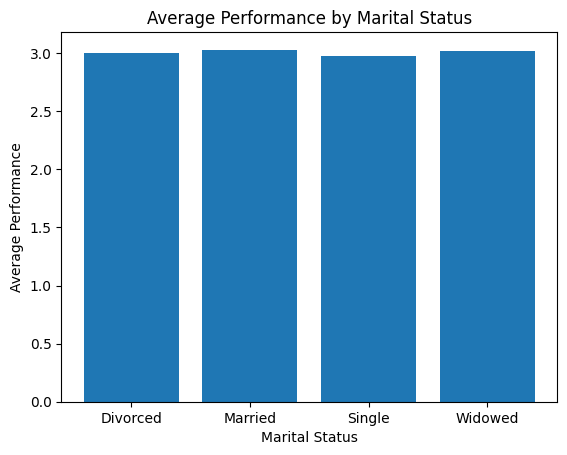

In [31]:
group=df.groupby("MaritalDesc")["Performance_Score_Num"].mean()
plt.bar(group.index,group.values)
plt.title("Average Performance by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Average Performance")
plt.show()


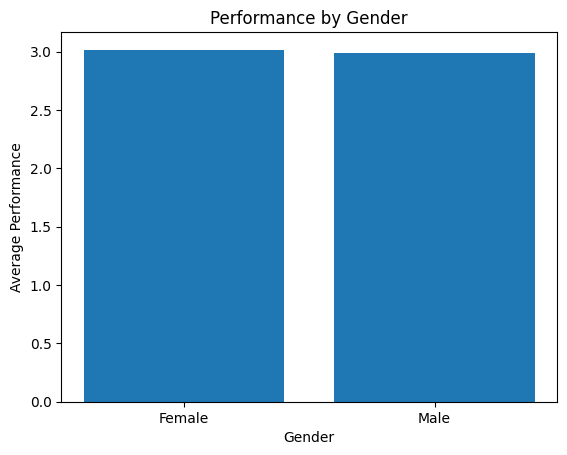

In [32]:
group=df.groupby("GenderCode")["Performance_Score_Num"].mean()
plt.bar(group.index,group.values)
plt.title("Performance by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Performance")
plt.show()


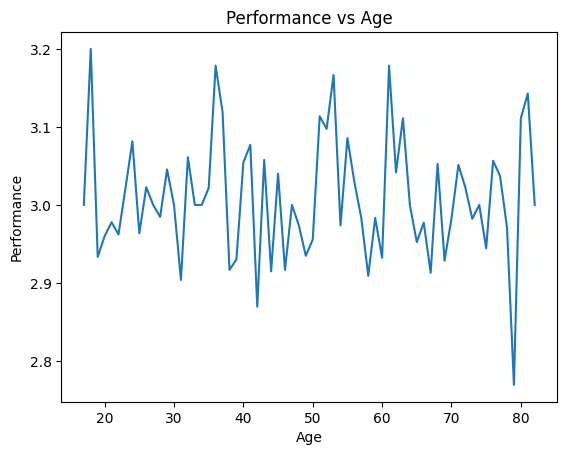

In [33]:
group=df.groupby("Age")["Performance_Score_Num"].mean()
plt.plot(group.index,group.values)
plt.title("Performance vs Age")
plt.xlabel("Age")
plt.ylabel("Performance")
plt.show()

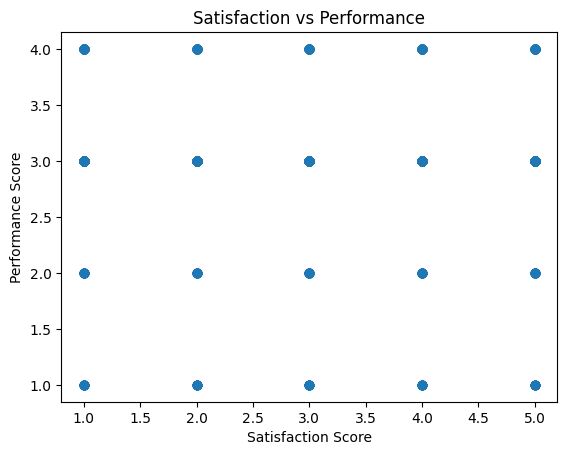

In [34]:
plt.scatter(df["Satisfaction Score"],df["Performance_Score_Num"])
plt.title("Satisfaction vs Performance")
plt.xlabel("Satisfaction Score")
plt.ylabel("Performance Score")
plt.show()


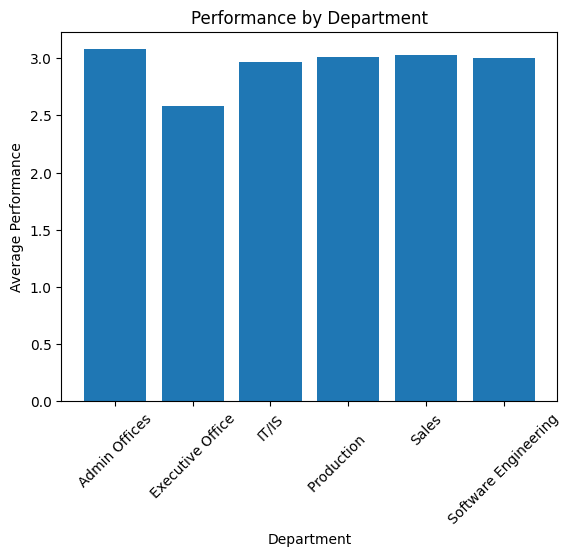

In [35]:
group=df.groupby("DepartmentType")["Performance_Score_Num"].mean()
plt.bar(group.index,group.values)
plt.xticks(rotation=45)
plt.title("Performance by Department")
plt.xlabel("Department")
plt.ylabel("Average Performance")
plt.show()


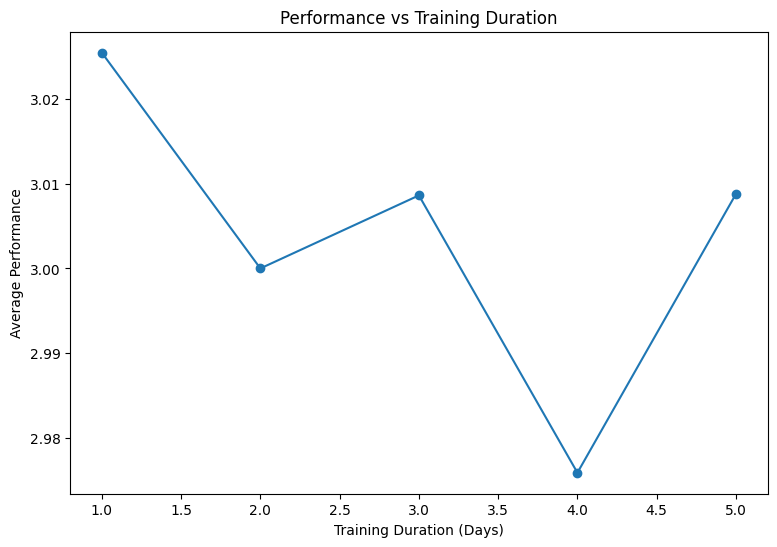

In [36]:
group=df.groupby("Training Duration(Days)")["Performance_Score_Num"].mean()
plt.figure(figsize=(9,6))
plt.plot(group.index,group.values,marker='o')
plt.title("Performance vs Training Duration")
plt.xlabel("Training Duration (Days)")
plt.ylabel("Average Performance")
plt.show()


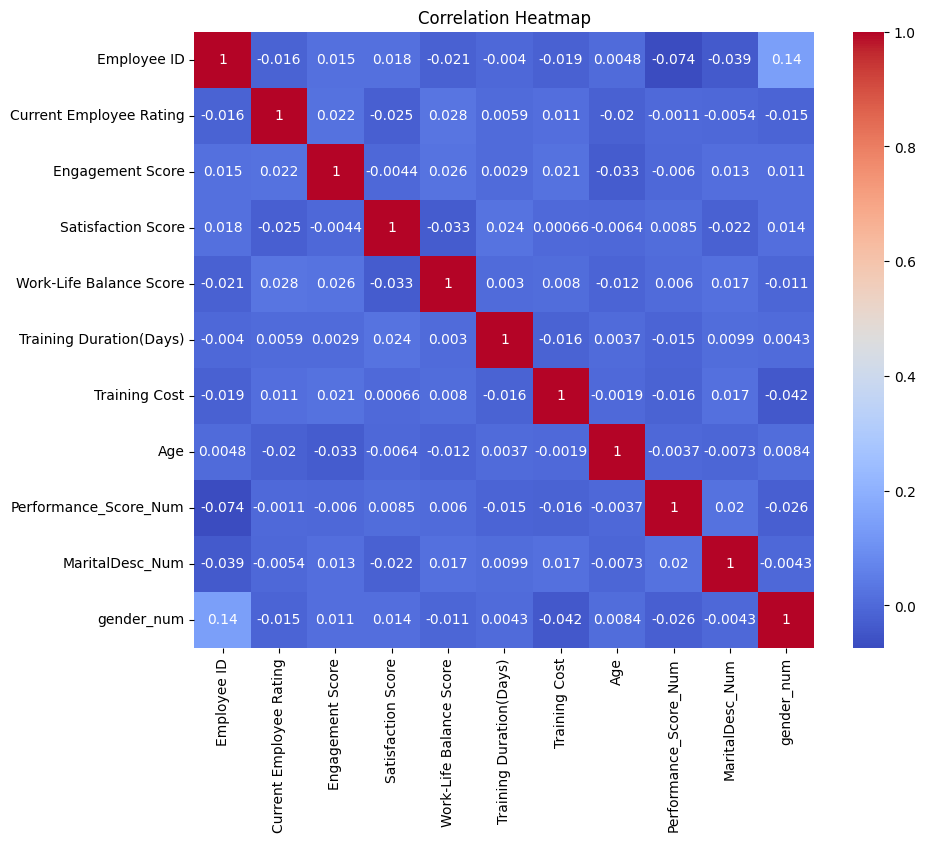

In [37]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()